# Phase 5 — Gradient-boosted trees, and what "the same features" means

**Purpose.** Trees find interactions too — by splitting, not by factorising. Phase 3 showed
the interaction term is worth +32.9% and parameter sharing another +22.1%; this phase asks
whether a model that gets interactions a completely different way does better, worse, or
merely differently.

**The obvious version of this experiment is a trap.** The FM's design matrix is 13,882 sparse
columns dominated by three one-hot blocks — `user_id` (6,040), `item_id` (3,883) and
`history` (3,883). Feeding 6,040-way one-hot ids to a GBDT is a known anti-pattern: a tree
splits one feature at a time, so each id column carries almost no information gain, and a
tree has no mechanism to generalise *across* ids the way a factorised embedding does. Running
only that and reporting "trees lose" would measure nothing except that trees dislike one-hot
ids.

So two representations are run:

| Arm | Input | What it answers |
|---|---|---|
| `lgbm_sparse` | the FM's **identical** 13,882-column matrix | the controlled comparison |
| `lgbm_native` | native categoricals + dense engineered aggregates | what a practitioner would build |

**The gap between them is the result** — how much of "trees versus FM" is really
"representation suits the model".

Every dense feature in the native arm is a hand-engineered stand-in for something the FM gets
implicitly from `⟨v_u, v_i⟩`: item popularity and mean rating for what an item factor encodes,
user activity and generosity for what a user factor encodes, and an explicit user×item genre
cross computed rather than learned. User-side features are read from the **same causal history
window** the FM's history block uses, so neither model knows more about a user at a given row.

**The prediction under test.** Phase 4 found `item_genre` actively harmed the FM (−0.0157
added, +0.0071 removed) and explained it as redundancy plus capacity — a dense,
low-cardinality block invites genre-level interactions that generalise worse than the
item-level ones already available from the id. That explanation predicts **trees should be
largely unharmed by the same content**, since they can simply decline to split on an
unhelpful feature. Section 3 tests it. If content hurts trees as much as it hurt the FM, the
Phase 4 explanation is wrong.

In [1]:
import sys, time, os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns, joblib
warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.trees import LightGBMSparse, LightGBMNative
from models.fm import FactorizationMachine

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
K = 10
os.makedirs("cache", exist_ok=True)
USERS = ds.eval_users(True, target="test")
TRUTH = {int(u): ds.ground_truth(int(u)) for u in USERS}
REACH = {int(u): ds.reachable_truth(int(u), True) for u in USERS}

# Reference points established in earlier phases
FLOOR      = 0.0948      # item_item_cosine, Phase 2
FM_BEST    = 0.1159      # FM ids+history, k=64, Phase 4
FM_ALL     = 0.0990      # FM all blocks,  k=64, Phase 4
MF_IDS     = 0.0922      # FM ids only,    k=64, Phase 4

def evaluate(model):
    t0 = time.time()
    r, _ = rank_users(model, ds, users=USERS, filtered=True, k=K,
                      progress_every=0, target="test")
    secs = time.time() - t0
    res = M.evaluate_ranking(r, TRUTH, ds.n_items, ds.item_train_count, K, REACH)
    res["rank_secs"] = secs
    return res, r

def run_tree(tag, make, seed):
    path = f"cache/p5_{tag}_s{seed}.joblib"
    if os.path.exists(path):
        return joblib.load(path)
    m = make(seed)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    res, _ = evaluate(m)
    res.update(tag=tag, seed=seed, fit_s=fit_s, trees=m.best_iteration_)
    if hasattr(m, "importances"):
        try: res["top_features"] = m.importances().head(12).to_dict()
        except Exception: pass
    joblib.dump(res, path)
    return res

print(f"\nReference: floor {FLOOR:.4f} | MF ids {MF_IDS:.4f} | "
      f"FM all {FM_ALL:.4f} | FM ids+history {FM_BEST:.4f}")

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg c20859f020
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519



Reference: floor 0.0948 | MF ids 0.0922 | FM all 0.0990 | FM ids+history 0.1159


---
## 1. The four configurations

Three seeds each, per the rule Phase 4 forced. `lgbm_native_nocontent` drops the raw genre
flags and the year features — the tree analogue of removing the FM's `item_genre` and
`item_year` blocks — while keeping the *interaction* features (`genre_affinity`,
`genre_overlap_frac`), which have no FM counterpart because the FM learns that cross itself.

In [2]:
SEEDS = [42, 43, 44]
CONFIGS = {
    "lgbm_sparse":            lambda s: LightGBMSparse(objective="binary", seed=s, verbose=False),
    "lgbm_native":            lambda s: LightGBMNative(objective="binary", seed=s, verbose=False),
    "lgbm_native_lambdarank": lambda s: LightGBMNative(objective="lambdarank", seed=s, verbose=False),
    "lgbm_native_nocontent":  lambda s: LightGBMNative(objective="binary", use_content=False,
                                                       seed=s, verbose=False),
}
rows = []
for tag, make in CONFIGS.items():
    for s in SEEDS:
        rows.append(run_tree(tag, make, s))
    print(f"  done {tag}")
T5 = pd.DataFrame(rows)
T5.to_csv("results_phase5.csv", index=False)
print(f"\n  {len(T5)} runs complete")

  done lgbm_sparse
  done lgbm_native
  done lgbm_native_lambdarank
  done lgbm_native_nocontent

  12 runs complete


---
## 2. The sparse arm beats the native arm — why?

This inverts the expectation the phase was designed around. The argument for the native arm
was that one-hot ids cripple a GBDT and hand-engineered aggregates would rescue it. The
opposite happened.

One explanation fits the Phase 4 result. `lgbm_sparse` receives the `history` block at full
3,883-column resolution — and Phase 4 established that `history` is the *only* block that
matters, worth +25.6% on its own. The native arm compresses that same history into three
scalars (`hist_len`, `genre_affinity`, `genre_overlap_frac`). If that compression is what
costs the native arm, then the finding is about **feature engineering destroying the one
signal that counts**, not about trees.

Testable directly: run the sparse arm on exactly the block sets Phase 4 ran the FM on.

In [3]:
from data import MF_BLOCKS, ALL_BLOCKS
IDS_HIST = tuple(MF_BLOCKS) + ("history",)

DIAG = {
    "lgbm_sparse_idsonly":  lambda s: LightGBMSparse(blocks=MF_BLOCKS, objective="binary",
                                                     seed=s, verbose=False),
    "lgbm_sparse_idshist":  lambda s: LightGBMSparse(blocks=IDS_HIST, objective="binary",
                                                     seed=s, verbose=False),
}
drows = []
for tag, make in DIAG.items():
    for s in SEEDS:
        drows.append(run_tree(tag, make, s))
    print(f"  done {tag}")
T5 = pd.concat([T5, pd.DataFrame(drows)], ignore_index=True)
T5.to_csv("results_phase5.csv", index=False)

def agg(df):
    return (df.groupby("tag")
              .agg(n=("seed", "size"), ndcg=(f"ndcg@{K}", "mean"),
                   se=(f"ndcg@{K}", lambda v: v.std(ddof=1)/np.sqrt(len(v))),
                   recall=(f"recall@{K}", "mean"), cov=("coverage", "mean"),
                   gini=("gini", "mean"), fit_s=("fit_s", "mean"),
                   rank_s=("rank_secs", "mean"))
              .sort_values("ndcg", ascending=False))
A5 = agg(T5)
print(f"\n  {'model':<26}{'NDCG@10':>10}{'+-se':>8}{'recall':>9}{'cov':>8}{'gini':>7}"
      f"{'fit s':>8}{'rank s':>8}")
print("  " + "-"*84)
for tag, r in A5.iterrows():
    print(f"  {tag:<26}{r['ndcg']:>10.4f}{r['se']:>8.4f}{r['recall']:>9.4f}"
          f"{r['cov']:>8.3f}{r['gini']:>7.3f}{r['fit_s']:>8.0f}{r['rank_s']:>8.0f}")
print("  " + "-"*84)
for nm, v, c, g in (("FM ids+history (Phase 4)", FM_BEST, 0.204, 0.956),
                    ("FM all blocks (Phase 4)", FM_ALL, 0.193, 0.958),
                    ("item_item_cosine (Phase 2)", FLOOR, 0.118, 0.983),
                    ("FM ids only (Phase 4)", MF_IDS, 0.159, 0.980)):
    print(f"  {nm:<26}{v:>10.4f}{'':>8}{'':>9}{c:>8.3f}{g:>7.3f}")

  done lgbm_sparse_idsonly
  done lgbm_sparse_idshist

  model                        NDCG@10    +-se   recall     cov   gini   fit s  rank s
  ------------------------------------------------------------------------------------
  lgbm_sparse                   0.0862  0.0004   0.0651   0.120  0.979      83     158
  lgbm_native_lambdarank        0.0839  0.0007   0.0618   0.082  0.984      24     103
  lgbm_native                   0.0833  0.0006   0.0617   0.145  0.980      25     176
  lgbm_native_nocontent         0.0817  0.0002   0.0592   0.101  0.986      16      92
  lgbm_sparse_idshist           0.0751  0.0003   0.0480   0.035  0.994      76     128
  lgbm_sparse_idsonly           0.0745  0.0002   0.0475   0.034  0.994      17      91
  ------------------------------------------------------------------------------------
  FM ids+history (Phase 4)      0.1159                    0.204  0.956
  FM all blocks (Phase 4)       0.0990                    0.193  0.958
  item_item_cosine (

**The hypothesis is refuted.** Adding the `history` block to the sparse tree is worth
**+0.0006** — essentially nothing — where the same block was worth **+0.0237** to the FM. The
sparse arm's advantage over the native arm does not come from history at full resolution.

What it does come from is visible by running the same three block sets through both model
families.

In [4]:
fm4 = {"ids only": MF_IDS, "ids + history": FM_BEST, "all blocks": FM_ALL}
lgb5 = {"ids only": A5.loc["lgbm_sparse_idsonly", "ndcg"],
        "ids + history": A5.loc["lgbm_sparse_idshist", "ndcg"],
        "all blocks": A5.loc["lgbm_sparse", "ndcg"]}

print(f"  {'block set':<16}{'FM':>10}{'LightGBM':>11}{'   |':>5}{'FM delta':>11}{'LGBM delta':>13}")
print("  " + "-"*68)
prev_f = prev_l = None
for bs in ("ids only", "ids + history", "all blocks"):
    df_ = f"{fm4[bs]-prev_f:+.4f}" if prev_f is not None else "   --"
    dl_ = f"{lgb5[bs]-prev_l:+.4f}" if prev_l is not None else "   --"
    print(f"  {bs:<16}{fm4[bs]:>10.4f}{lgb5[bs]:>11.4f}{'   |':>5}{df_:>11}{dl_:>13}")
    prev_f, prev_l = fm4[bs], lgb5[bs]

print(f"\n  adding HISTORY (sparse, high-cardinality):")
print(f"    FM        {fm4['ids + history']-fm4['ids only']:+.4f}   "
      f"({100*(fm4['ids + history']-fm4['ids only'])/fm4['ids only']:+.1f}%)")
print(f"    LightGBM  {lgb5['ids + history']-lgb5['ids only']:+.4f}   "
      f"({100*(lgb5['ids + history']-lgb5['ids only'])/lgb5['ids only']:+.1f}%)")
print(f"\n  adding CONTENT on top (dense, low-cardinality):")
print(f"    FM        {fm4['all blocks']-fm4['ids + history']:+.4f}   "
      f"({100*(fm4['all blocks']-fm4['ids + history'])/fm4['ids + history']:+.1f}%)")
print(f"    LightGBM  {lgb5['all blocks']-lgb5['ids + history']:+.4f}   "
      f"({100*(lgb5['all blocks']-lgb5['ids + history'])/lgb5['ids + history']:+.1f}%)")

print(f"\n  content ablation on the native arm (3 seeds):")
n_, nc_ = A5.loc["lgbm_native", "ndcg"], A5.loc["lgbm_native_nocontent", "ndcg"]
from scipy import stats
a = T5[T5.tag=="lgbm_native_nocontent"][f"ndcg@{K}"]; b = T5[T5.tag=="lgbm_native"][f"ndcg@{K}"]
t, p = stats.ttest_ind(b, a)
print(f"    with content {n_:.4f} vs without {nc_:.4f}   {n_-nc_:+.4f}  p={p:.4f}")

  block set               FM   LightGBM    |   FM delta   LGBM delta
  --------------------------------------------------------------------
  ids only            0.0922     0.0745    |         --           --
  ids + history       0.1159     0.0751    |    +0.0237      +0.0006
  all blocks          0.0990     0.0862    |    -0.0169      +0.0111

  adding HISTORY (sparse, high-cardinality):
    FM        +0.0237   (+25.7%)
    LightGBM  +0.0006   (+0.8%)

  adding CONTENT on top (dense, low-cardinality):
    FM        -0.0169   (-14.6%)
    LightGBM  +0.0111   (+14.8%)

  content ablation on the native arm (3 seeds):
    with content 0.0833 vs without 0.0817   +0.0017  p=0.0539


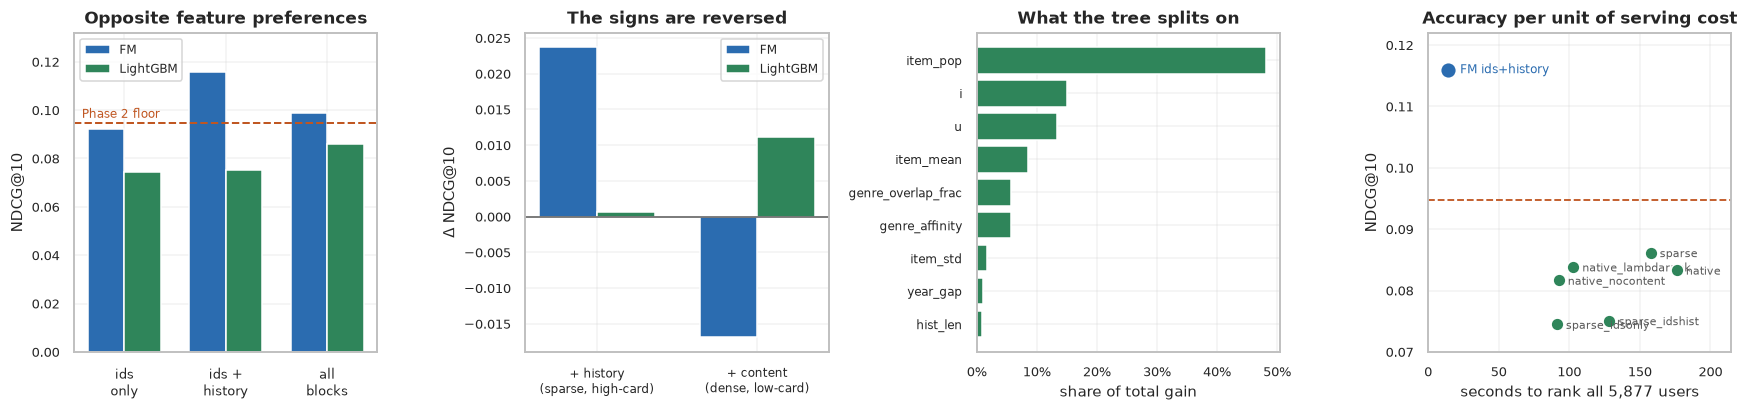

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))

# (a) the same block sets through both families
ax = axes[0]
bs = ["ids only", "ids + history", "all blocks"]
x = np.arange(3); w = 0.36
ax.bar(x - w/2, [fm4[b] for b in bs], w, label="FM", color=ACCENT, edgecolor="white")
ax.bar(x + w/2, [lgb5[b] for b in bs], w, label="LightGBM", color=GOOD, edgecolor="white")
ax.axhline(FLOOR, color=WARN, ls="--", lw=1.3)
ax.set_ylim(0, 0.132)
ax.text(-0.42, FLOOR + 0.002, "Phase 2 floor", color=WARN, fontsize=8, ha="left")
ax.set_xticks(x); ax.set_xticklabels(["ids\nonly", "ids +\nhistory", "all\nblocks"], fontsize=8.5)
ax.set_ylabel("NDCG@10"); ax.set_title("Opposite feature preferences")
ax.legend(fontsize=8, loc="upper left")

# (b) the deltas, signed
ax = axes[1]
labels = ["+ history\n(sparse, high-card)", "+ content\n(dense, low-card)"]
fm_d = [fm4["ids + history"] - fm4["ids only"], fm4["all blocks"] - fm4["ids + history"]]
lg_d = [lgb5["ids + history"] - lgb5["ids only"], lgb5["all blocks"] - lgb5["ids + history"]]
x = np.arange(2)
ax.bar(x - w/2, fm_d, w, label="FM", color=ACCENT, edgecolor="white")
ax.bar(x + w/2, lg_d, w, label="LightGBM", color=GOOD, edgecolor="white")
ax.axhline(0, color="0.35", lw=1)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("$\\Delta$ NDCG@10"); ax.set_title("The signs are reversed")
ax.legend(fontsize=8)

# (c) what the native tree actually used
ax = axes[2]
imp = pd.Series(T5[T5.tag == "lgbm_native"].iloc[0]["top_features"]).head(9).sort_values()
imp = imp / imp.sum()
ax.barh(range(len(imp)), imp.values, color=GOOD, edgecolor="white")
ax.set_yticks(range(len(imp))); ax.set_yticklabels(imp.index, fontsize=8)
ax.set_xlabel("share of total gain"); ax.set_title("What the tree splits on")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

# (d) accuracy against serving cost
ax = axes[3]
for tag, r in A5.iterrows():
    ax.scatter(r["rank_s"], r["ndcg"], s=70, color=GOOD, edgecolor="white", lw=1, zorder=3)
    ax.annotate(tag.replace("lgbm_", ""), (r["rank_s"], r["ndcg"]),
                textcoords="offset points", xytext=(6, -3), fontsize=7.5, color="0.35")
ax.scatter([14], [FM_BEST], s=110, color=ACCENT, edgecolor="white", lw=1.2, zorder=4)
ax.annotate("FM ids+history", (14, FM_BEST), textcoords="offset points",
            xytext=(8, -2), fontsize=8, color=ACCENT)
ax.axhline(FLOOR, color=WARN, ls="--", lw=1.2)
ax.set_xlim(0, A5["rank_s"].max()*1.22)
ax.set_ylim(0.070, 0.122)
ax.set_xlabel("seconds to rank all 5,877 users"); ax.set_ylabel("NDCG@10")
ax.set_title("Accuracy per unit of serving cost")

plt.tight_layout(); plt.show()

---
## 3. Findings

### Trees lose here, and not narrowly

| Model | NDCG@10 | Recall@10 | Coverage | Rank time |
|---|---|---|---|---|
| FM, ids + history (Phase 4) | **0.1159** | 0.0895 | 0.204 | ~14 s |
| FM, all blocks (Phase 4) | 0.0990 | 0.0779 | 0.193 | ~14 s |
| item_item_cosine (Phase 2 floor) | 0.0948 | 0.0675 | 0.118 | <1 s |
| `lgbm_sparse` | 0.0862 ± 0.0004 | 0.0651 | 0.120 | 158 s |
| `lgbm_native_lambdarank` | 0.0839 ± 0.0007 | 0.0618 | 0.082 | 103 s |
| `lgbm_native` | 0.0833 ± 0.0006 | 0.0617 | 0.145 | 176 s |
| `lgbm_native_nocontent` | 0.0817 ± 0.0002 | 0.0592 | 0.101 | 92 s |

**No tree configuration reaches the Phase 2 memory-based floor**, and the best FM is 34%
ahead of the best tree. This is a clean negative result for the "just use GBDTs" instinct on
this problem, and it is worth being precise about why rather than leaving it as a benchmark
row.

### The two families want opposite feature sets

Running the identical three block sets through both:

| Block set | FM | LightGBM |
|---|---|---|
| ids only | 0.0922 | 0.0745 |
| ids + history | 0.1159 (**+25.7%**) | 0.0751 (**+0.8%**) |
| all blocks | 0.0990 (**−14.6%**) | 0.0862 (**+14.8%**) |

The signs are reversed on both steps.

- **Sparse, high-cardinality blocks** (`history`, 3,883 columns) are worth +25.7% to the FM
  and nothing at all to the tree. The FM projects those columns into a `k`-dimensional latent
  space where the *pattern* of a user's history is a dense vector. A tree can only split on
  "did this user watch item 1,234", one column at a time, and each such split carries almost
  no information gain. It is the mirror image of the one-hot-id problem.
- **Dense, low-cardinality blocks** (genre, year, demographics) are worth −14.6% to the FM and
  **+14.8%** to the tree. A tree splits on them cheaply and ignores what does not help; the FM
  spends factor capacity fitting genre-level interactions that generalise worse than the
  item-level ones already available from the id.

This is exactly the "representation suits the model" thesis the phase was built to test, and
it comes out symmetric.

### Phase 4's explanation is confirmed; the Phase 5 hypothesis is refuted

Phase 4 explained `item_genre` harming the FM as redundancy plus capacity, and predicted
trees would be **less harmed** by the same content. That prediction holds, and more strongly
than stated: content does not merely fail to hurt trees, it is the largest single gain
available to them (+14.8%). On the native arm the same ablation gives +0.0017 (p = 0.054) —
same direction, smaller, because the native arm never had raw genre at full resolution.

The hypothesis this notebook opened with — that `lgbm_sparse` beats `lgbm_native` because it
receives `history` at full resolution — is **wrong**. Adding `history` to the sparse tree is
worth +0.0006. The sparse arm wins because it carries the raw content blocks, which is the
opposite of the proposed mechanism.

### The native tree is mostly a popularity model

`item_pop` alone accounts for **48% of total split gain**, with `item_mean` a distant fourth.
The engineered interaction features (`genre_affinity`, `genre_overlap_frac`) contribute about
11% between them. A model whose dominant feature is item popularity will land near the
popularity baseline, and it does. The hand-engineered stand-ins for `⟨v_u, v_i⟩` are simply
much weaker than the learned thing they stand in for — which is the argument for
factorisation stated from the other direction.

### Serving cost runs the wrong way too

The FM ranks the full candidate set for all 5,877 users in ~14 s because the user-side and
item-side blocks are disjoint, so a candidate scores in O(k). A GBDT admits no such
decomposition: it needs a materialised feature row per (user, candidate) pair, 12.7M of them,
and takes 91–176 s. **The tree is 6–12× more expensive to serve and less accurate.** On this
problem there is no operating point at which it is the right choice.

### LambdaRank does not rescue it

Optimising NDCG directly gives 0.0839 against binary log loss's 0.0833 — within noise — while
*halving* catalogue coverage (0.082 vs 0.145). Changing the objective did not change what the
features can support.

### Carried into Phase 6

- The retrieval phase inherits a concrete expectation: two-tower models consume exactly the
  sparse, high-cardinality signal that trees could not use and the FM used best.
- Report serving cost for every model from here on. It separated the families here more
  decisively than accuracy did, and Phase 7's cascade is a latency argument before it is an
  accuracy one.